<a href="https://colab.research.google.com/github/reshmiee/Disha/blob/main/person2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install routellm litellm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.6/36.6 MB 31.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 66.4 MB/s  0:00:00
  Attempting uninstall: importlib-metadata
    Found existing installation: importlib_metadata 9.0.1
    Uninstalling importlib_metadata-9.0.1:
      Successfully uninstalled importlib_metadata-9.0.1
  Attempting uninstall: filelock
    Found existing installation: filelock 4.2.4
    Uninstalling filelock-4.2.4:
      Successfully uninstalled filelock-4.2.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [routellm]


In [ ]:
import os
os.environ["OPENAI_API_KEY"] = "dummy-key-not-used"

from routellm.controller import Controller

client = Controller(
    routers=["bert"],
    strong_model="gpt-4-1106-preview",
    weak_model="mistralai/Mixtral-8x7B-Instruct-v0.1",
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
import pandas as pd

qs = pd.Series([
    "Why does the moon have phases?",
    "Moon ke phases kyun hote hain?",
])

scores = client.batch_calculate_win_rate(prompts=qs, router="bert")
print(scores)

0    0.330124
1    0.346364
dtype: float32


In [ ]:
print([m for m in dir(client) if not m.startswith("_")])

['acompletion', 'api_base', 'api_key', 'batch_calculate_win_rate', 'chat', 'completion', 'model_counts', 'model_pair', 'progress_bar', 'route', 'routers']


In [ ]:
r = client.routers["bert"]
print(type(r))
print([a for a in dir(r) if not a.startswith("_")])

<class 'routellm.routers.routers.BERTRouter'>
['NO_PARALLEL', 'calculate_strong_win_rate', 'model', 'route', 'tokenizer']


In [ ]:
r = client.routers["bert"]
tok = r.tokenizer

print("Tokenizer class:", type(tok).__name__)
print("Tokenizer name:", tok.name_or_path)
print("Model name:", r.model.config._name_or_path)

for q in ["Why does the moon have phases?", "Moon ke phases kyun hote hain?"]:
    toks = tok.tokenize(q)
    print(len(q.split()), "words ->", len(toks), "tokens:", toks)

Tokenizer class: XLMRobertaTokenizer
Tokenizer name: routellm/bert_gpt4_augmented
Model name: routellm/bert_gpt4_augmented
6 words -> 9 tokens: ['▁Why', '▁does', '▁the', '▁', 'moon', '▁have', '▁phase', 's', '?']
6 words -> 10 tokens: ['▁Moon', '▁ke', '▁phase', 's', '▁ky', 'un', '▁ho', 'te', '▁hain', '?']


In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("routellm/bert_gpt4_augmented")

config.json:   0%|          | 0.00/924 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, datetime
import numpy as np
import pandas as pd

tok = client.routers["bert"].tokenizer      # the router's own tokenizer, not a separate one
router = client.routers["bert"]

BASE = '/content/drive/MyDrive/ML_Research'   # <- change to your shared folder
for sub in ['data', 'scores', 'features', 'results']:
    os.makedirs(f'{BASE}/{sub}', exist_ok=True)

def save_versioned(df, folder, stem):
    v = 1
    while os.path.exists(f'{BASE}/{folder}/{stem}_v{v}.csv'):
        v += 1
    path = f'{BASE}/{folder}/{stem}_v{v}.csv'
    df.to_csv(path, index=False)
    print('saved', path, df.shape)
    return path

bench = pd.read_excel(f'{BASE}/data/benchmark_v1.xlsx', sheet_name='Benchmark')
bench = bench.dropna(subset=['english', 'hinglish']).reset_index(drop=True)
bench['english'] = bench['english'].astype(str).str.strip()
bench['hinglish'] = bench['hinglish'].astype(str).str.strip()
assert bench['pair_id'].is_unique
print(len(bench), 'pairs loaded')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
80 pairs loaded


In [ ]:
def score(texts):
    s = client.batch_calculate_win_rate(prompts=pd.Series(list(texts)), router='bert')
    return [float(x) for x in s]

scores = pd.DataFrame({
    'pair_id': bench['pair_id'],
    'english_score': score(bench['english']),
    'hinglish_score': score(bench['hinglish']),
})
scores['diff_en_minus_hi'] = scores['english_score'] - scores['hinglish_score']

# make sure batch output lines up with the input rows
for i in [0, len(bench) // 2, len(bench) - 1]:
    e = float(router.calculate_strong_win_rate(bench.loc[i, 'english']))
    h = float(router.calculate_strong_win_rate(bench.loc[i, 'hinglish']))
    assert abs(e - scores.loc[i, 'english_score']) < 1e-3, f'order mismatch, row {i}'
    assert abs(h - scores.loc[i, 'hinglish_score']) < 1e-3, f'order mismatch, row {i}'

# sanity checks, then save to Drive straight away
assert len(scores) == len(bench)
assert scores[['english_score', 'hinglish_score']].notna().all().all()
assert scores[['english_score', 'hinglish_score']].apply(lambda c: c.between(0, 1)).all().all()
save_versioned(scores, 'scores', 'scores')

saved /content/drive/MyDrive/ML_Research/scores/scores_v1.csv (80, 4)


'/content/drive/MyDrive/ML_Research/scores/scores_v1.csv'

In [ ]:
feat = pd.DataFrame({'pair_id': bench['pair_id']})
for lang, col in [('en', 'english'), ('hi', 'hinglish')]:
    feat[f'{lang}_words'] = bench[col].map(lambda t: len(t.split()))
    feat[f'{lang}_tokens'] = bench[col].map(lambda t: len(tok.tokenize(t)))
    feat[f'{lang}_fertility'] = feat[f'{lang}_tokens'] / feat[f'{lang}_words']
feat['tokens_diff_hi_minus_en'] = feat['hi_tokens'] - feat['en_tokens']
save_versioned(feat, 'features', 'features')

import importlib.metadata as im
def ver(p):
    try: return im.version(p)
    except Exception: return 'unknown'

config = {
    'router_checkpoint': 'routellm/bert_gpt4_augmented',
    'strong_model_label': 'gpt-4-1106-preview',
    'weak_model_label': 'mistralai/Mixtral-8x7B-Instruct-v0.1',
    'threshold': None,   # fix this before analysis, see below
    'routellm_version': ver('routellm'),
    'run_date_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
}
with open(f'{BASE}/results/config_v1.json', 'w') as f:
    json.dump(config, f, indent=2)
print(config)

saved /content/drive/MyDrive/ML_Research/features/features_v1.csv (80, 8)
{'router_checkpoint': 'routellm/bert_gpt4_augmented', 'strong_model_label': 'gpt-4-1106-preview', 'weak_model_label': 'mistralai/Mixtral-8x7B-Instruct-v0.1', 'threshold': None, 'routellm_version': '0.2.0', 'run_date_utc': '2026-10-24T14:27:30+00:00'}


In [ ]:
d = scores['diff_en_minus_hi']
print('mean English / Hinglish score:', round(scores.english_score.mean(), 4), round(scores.hinglish_score.mean(), 4))
print('mean diff (EN - HI):', round(d.mean(), 4), '| English higher in', int((d > 0).sum()), 'of', len(d))
print('score range:', round(min(scores.english_score.min(), scores.hinglish_score.min()), 3),
      'to', round(max(scores.english_score.max(), scores.hinglish_score.max()), 3))
print('share of scores >= 0.5 (EN, HI):', round((scores.english_score >= 0.5).mean(), 3),
      round((scores.hinglish_score >= 0.5).mean(), 3))
print('mean tokens per word (EN, HI):', round(feat.en_fertility.mean(), 3), round(feat.hi_fertility.mean(), 3))

mean English / Hinglish score: 0.4091 0.4441
mean diff (EN - HI): -0.0351 | English higher in 30 of 80
score range: 0.065 to 0.786
share of scores >= 0.5 (EN, HI): 0.275 0.25
mean tokens per word (EN, HI): 1.352 1.397


In [ ]:
from scipy import stats
d = scores['diff_en_minus_hi']
print('paired t-test:', stats.ttest_rel(scores.english_score, scores.hinglish_score))
print('Wilcoxon:', stats.wilcoxon(d))
print('effect size (dz):', round(d.mean() / d.std(), 3))

# does the router separate easy from hard at all?
print(scores.assign(difficulty=bench['difficulty'])
      .groupby('difficulty')[['english_score', 'hinglish_score']].mean().round(3))

# biggest disagreements: check these pairs for meaning differences first
chk = bench[['pair_id', 'difficulty', 'english', 'hinglish']].assign(diff=d)
print(chk.reindex(d.abs().sort_values(ascending=False).index).head(8)[['pair_id', 'difficulty', 'diff']])

paired t-test: TtestResult(statistic=np.float64(-3.599860047669046), pvalue=np.float64(0.000553870636627743), df=np.int64(79))
Wilcoxon: WilcoxonResult(statistic=np.float64(920.0), pvalue=np.float64(0.000786789037616073))
effect size (dz): -0.402
            english_score  hinglish_score
difficulty                               
Easy                0.313           0.394
Hard                0.483           0.481
Medium              0.399           0.446
Very Hard           0.441           0.453
    pair_id difficulty      diff
75       76       Easy -0.343555
18       19     Medium -0.256088
78       79       Easy -0.231314
15       16     Medium -0.209709
79       80       Easy -0.204470
30       31       Hard  0.189086
67       68       Easy -0.183988
71       72       Easy -0.183195


In [ ]:
g = pd.DataFrame({'batch': np.where(bench['pair_id'] <= 60, 'IDs 1-60', 'IDs 61-80'),
                  'difficulty': bench['difficulty'], 'diff': d})
print(g.groupby('batch')['diff'].agg(['count', 'mean', 'std']).round(3))
print(g[g.difficulty == 'Easy'].groupby('batch')['diff'].agg(['count', 'mean']).round(3))

print('Spearman(diff, token diff):', stats.spearmanr(d, feat['tokens_diff_hi_minus_en']))
print('Spearman(diff, word diff):', stats.spearmanr(d, feat['hi_words'] - feat['en_words']))

           count   mean    std
batch                         
IDs 1-60      60 -0.018  0.075
IDs 61-80     20 -0.085  0.102
           count   mean
batch                  
IDs 1-60       5 -0.064
IDs 61-80     20 -0.085
Spearman(diff, token diff): SignificanceResult(statistic=np.float64(0.16975740720184254), pvalue=np.float64(0.1322188951297867))
Spearman(diff, word diff): SignificanceResult(statistic=np.float64(0.06717004173591624), pvalue=np.float64(0.5538500437097342))


In [ ]:
!pip install -q pandarallel
%cd /content/RouteLLM
!python -m routellm.calibrate_threshold --task calibrate --routers bert --strong-model-pct 0.5 --config config.example.yaml
%cd /content

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/RouteLLM
README.md: 100% 418/418 [00:00<00:00, 1.25MB/s]

data/train-00000-of-00001.parquet: downloading bytes:  36% 765k/2.11M [00:01<00:02, 528kB/s, 20.6kB/s  ]
data/train-00000-of-00001.parquet: downloading bytes: 100% 1.86M/1.86M [00:01<00:00, 1.07MB/s,  176kB/s  ]
data/train-00000-of-00001.parquet: reconstructing file: 100% 2.11M/2.11M [00:01<00:00, 1.22MB/s,  200kB/s  ]
Generating train split: 100% 57477/57477 [00:00<00:00, 479045.89 examples/s]
For 50.0% strong model calls for bert, threshold = 0.4066
/content


In [ ]:
cfg = json.load(open(f'{BASE}/results/config_v1.json'))
cfg['threshold'] = 0.4066
cfg['threshold_source'] = 'routellm.calibrate_threshold, bert, Chatbot Arena reference data (57,477 prompts), strong-model-pct 0.5'
cfg['threshold_set_on'] = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')
with open(f'{BASE}/results/config_v2.json', 'w') as f:
    json.dump(cfg, f, indent=2)
print(cfg)

{'router_checkpoint': 'routellm/bert_gpt4_augmented', 'strong_model_label': 'gpt-4-1106-preview', 'weak_model_label': 'mistralai/Mixtral-8x7B-Instruct-v0.1', 'threshold': 0.4066, 'routellm_version': '0.2.0', 'run_date_utc': '2026-10-24T14:27:30+00:00', 'threshold_source': 'routellm.calibrate_threshold, bert, Chatbot Arena reference data (57,477 prompts), strong-model-pct 0.5', 'threshold_set_on': '2026-10-24T15:09:23+00:00'}


In [ ]:
import subprocess, re, json

def calibrate(pct):
    r = subprocess.run(
        ['python', '-m', 'routellm.calibrate_threshold', '--task', 'calibrate',
         '--routers', 'bert', '--strong-model-pct', str(pct),
         '--config', 'config.example.yaml'],
        cwd='/content/RouteLLM', capture_output=True, text=True)
    out = r.stdout + r.stderr
    m = re.search(r'threshold = (\d+\.\d+)', out)
    assert m, 'could not find the threshold in the output:\n' + out[-1500:]
    print(f'{pct:.0%} strong calls -> threshold {m.group(1)}')
    return float(m.group(1))

t30 = calibrate(0.3)
t70 = calibrate(0.7)

cfg = json.load(open(f'{BASE}/results/config_v2.json'))
# fewer strong calls needs a higher cut-off, more strong calls a lower one
assert t70 < cfg['threshold'] < t30, f"unexpected order: {t70}, {cfg['threshold']}, {t30}"

cfg['threshold_30pct'] = t30
cfg['threshold_70pct'] = t70
with open(f'{BASE}/results/config_v2.json', 'w') as f:
    json.dump(cfg, f, indent=2)
print(cfg)

30% strong calls -> threshold 0.46514
70% strong calls -> threshold 0.33721
{'router_checkpoint': 'routellm/bert_gpt4_augmented', 'strong_model_label': 'gpt-4-1106-preview', 'weak_model_label': 'mistralai/Mixtral-8x7B-Instruct-v0.1', 'threshold': 0.4066, 'routellm_version': '0.2.0', 'run_date_utc': '2026-10-24T14:27:30+00:00', 'threshold_source': 'routellm.calibrate_threshold, bert, Chatbot Arena reference data (57,477 prompts), strong-model-pct 0.5', 'threshold_set_on': '2026-10-24T15:09:23+00:00', 'threshold_30pct': 0.46514, 'threshold_70pct': 0.33721}


In [ ]:
for i in [76, 79, 80, 19, 16, 68, 72, 31]:
    r = bench[bench.pair_id == i].iloc[0]
    print(f"[{i}] {r.difficulty}\nEN: {r.english}\nHI: {r.hinglish}\n")

[76] Easy
EN: Write a short paragraph about the importance of saving water.
HI: Paani bachane ke importance pe ek chhota paragraph likho.

[79] Easy
EN: Give three tips for staying productive while studying.
HI: Padhai karte waqt productive rehne ke teen tips do.

[80] Easy
EN: Write a short apology message to a friend for being late.
HI: Late hone ke liye ek dost ko chhota sa apology message likho.

[19] Medium
EN: Imagine that a college has limited funding but wants to improve student learning. What practical steps would you recommend?
HI: Imagine karo ki ek college ke paas limited funding hai, lekin woh students ki learning improve karna chahta hai. Tum kaunse practical steps recommend karoge?

[16] Medium
EN: Do you think artificial intelligence will create more jobs than it replaces? Explain your reasoning.
HI: Kya tumhe lagta hai ki artificial intelligence jitni jobs replace karegi, usse zyada new jobs create karegi? Apna reasoning explain karo.

[68] Easy
EN: Why does ice float 

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
from scipy import stats

cfg = json.load(open(f'{BASE}/results/config_v2.json'))
d = scores['diff_en_minus_hi']          # positive = English scored higher
rng = np.random.default_rng(0)

def boot_ci(x, n=10000):
    x = np.asarray(x)
    m = rng.choice(x, size=(n, len(x))).mean(axis=1)
    return np.percentile(m, [2.5, 97.5])

# ---------- 1. Overall score gap ----------
lo, hi = boot_ci(d)
print('=== OVERALL SCORE GAP (EN minus HI) ===')
print(f'mean EN {scores.english_score.mean():.4f} | mean HI {scores.hinglish_score.mean():.4f}')
print(f'mean diff {d.mean():.4f}, 95% bootstrap CI [{lo:.4f}, {hi:.4f}]')
print(f'effect size dz {d.mean()/d.std():.3f}')
print('paired t:', stats.ttest_rel(scores.english_score, scores.hinglish_score))
print('Wilcoxon:', stats.wilcoxon(d))
print(f'Hinglish higher in {(d<0).sum()} pairs, English higher in {(d>0).sum()}, ties {(d==0).sum()}\n')

# ---------- 2. Routing decisions at three thresholds ----------
rows = []
for name, t in [('30% strong', cfg['threshold_30pct']),
                ('50% strong', cfg['threshold']),
                ('70% strong', cfg['threshold_70pct'])]:
    en = scores.english_score >= t
    hi_ = scores.hinglish_score >= t
    both = int((en & hi_).sum()); neither = int((~en & ~hi_).sum())
    en_only = int((en & ~hi_).sum())     # English -> strong, Hinglish -> weak
    hi_only = int((~en & hi_).sum())     # Hinglish -> strong, English -> weak
    p = mcnemar([[both, en_only], [hi_only, neither]], exact=True).pvalue
    rows.append({'setting': name, 'threshold': round(t, 4),
                 'EN_strong_pct': round(100*en.mean(), 1),
                 'HI_strong_pct': round(100*hi_.mean(), 1),
                 'EN_only_strong': en_only, 'HI_only_strong': hi_only,
                 'same_route': both + neither,
                 'net_gap_pct (EN-HI)': round(100*(en_only - hi_only)/len(scores), 1),
                 'mcnemar_p': round(p, 4)})
gap = pd.DataFrame(rows)
print('=== ROUTING DECISIONS ===')
print(gap.to_string(index=False))
save_versioned(gap, 'results', 'routing_gap')

# ---------- 3. Breakdowns ----------
def breakdown(col):
    out = []
    for g, idx in bench.groupby(col).groups.items():
        x = d.loc[idx]
        l, h = boot_ci(x)
        out.append({col: g, 'n': len(x), 'mean_diff': round(x.mean(), 3),
                    'ci_low': round(l, 3), 'ci_high': round(h, 3),
                    'wilcoxon_p': round(stats.wilcoxon(x).pvalue, 4) if (x != 0).any() else np.nan})
    return pd.DataFrame(out)

print('\n=== BY DIFFICULTY ===')
by_diff = breakdown('difficulty'); print(by_diff.to_string(index=False))
save_versioned(by_diff, 'results', 'gap_by_difficulty')

cat_col = 'main_category' if 'main_category' in bench.columns else 'task_type'
print(f'\n=== BY {cat_col.upper()} ===')
by_cat = breakdown(cat_col); print(by_cat.to_string(index=False))
save_versioned(by_cat, 'results', 'gap_by_category')

print('\n=== CATEGORY x DIFFICULTY (mean diff, n) ===')
print(pd.pivot_table(pd.DataFrame({'cat': bench[cat_col], 'diff_level': bench['difficulty'], 'd': d}),
                     index='cat', columns='diff_level', values='d', aggfunc=['mean', 'count']).round(3))

=== OVERALL SCORE GAP (EN minus HI) ===
mean EN 0.4091 | mean HI 0.4441
mean diff -0.0351, 95% bootstrap CI [-0.0545, -0.0166]
effect size dz -0.402
paired t: TtestResult(statistic=np.float64(-3.599860047669046), pvalue=np.float64(0.000553870636627743), df=np.int64(79))
Wilcoxon: WilcoxonResult(statistic=np.float64(920.0), pvalue=np.float64(0.000786789037616073))
Hinglish higher in 50 pairs, English higher in 30, ties 0

=== ROUTING DECISIONS ===
   setting  threshold  EN_strong_pct  HI_strong_pct  EN_only_strong  HI_only_strong  same_route  net_gap_pct (EN-HI)  mcnemar_p
30% strong     0.4651           38.8           41.2               4               6          70                 -2.5     0.7539
50% strong     0.4066           55.0           71.2               1              14          65                -16.2     0.0010
70% strong     0.3372           72.5           90.0               0              14          66                -17.5     0.0001
saved /content/drive/MyDrive/ML_Resea

In [ ]:
!pip install -q routellm litellm statsmodels

In [ ]:
import os, json, datetime
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

os.environ["OPENAI_API_KEY"] = "dummy-key-not-used"   # BERT router makes no OpenAI calls
from routellm.controller import Controller

client = Controller(
    routers=["bert"],
    strong_model="gpt-4-1106-preview",
    weak_model="mistralai/Mixtral-8x7B-Instruct-v0.1",
)
router = client.routers["bert"]
tok = router.tokenizer

BASE = '/content/drive/MyDrive/ML_Research'

def save_versioned(df, folder, stem):
    v = 1
    while os.path.exists(f'{BASE}/{folder}/{stem}_v{v}.csv'):
        v += 1
    path = f'{BASE}/{folder}/{stem}_v{v}.csv'
    df.to_csv(path, index=False)
    print('saved', path, df.shape)
    return path

def score(texts):
    s = client.batch_calculate_win_rate(prompts=pd.Series(list(texts)), router='bert')
    return [float(x) for x in s]

print(json.load(open(f'{BASE}/results/config_v2.json')))   # thresholds should show up here

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'router_checkpoint': 'routellm/bert_gpt4_augmented', 'strong_model_label': 'gpt-4-1106-preview', 'weak_model_label': 'mistralai/Mixtral-8x7B-Instruct-v0.1', 'threshold': 0.4066, 'routellm_version': '0.2.0', 'run_date_utc': '2026-10-24T14:27:30+00:00', 'threshold_source': 'routellm.calibrate_threshold, bert, Chatbot Arena reference data (57,477 prompts), strong-model-pct 0.5', 'threshold_set_on': '2026-10-24T15:09:23+00:00', 'threshold_30pct': 0.46514, 'threshold_70pct': 0.33721}


In [ ]:
def load(path):
    b = pd.read_excel(path, sheet_name='Benchmark')
    b = b.dropna(subset=['english', 'hinglish']).reset_index(drop=True)
    b['english'] = b['english'].astype(str).str.strip()
    b['hinglish'] = b['hinglish'].astype(str).str.strip()
    return b

b1 = load(f'{BASE}/data/benchmark_v1.xlsx')
bench = load(f'{BASE}/data/benchmark_v2.xlsx')
assert bench['pair_id'].is_unique and len(bench) == 80

m = b1.merge(bench, on='pair_id', suffixes=('_v1', '_v2'))
changed = m[(m.english_v1 != m.english_v2) | (m.hinglish_v1 != m.hinglish_v2)].pair_id.tolist()
print('changed pairs:', changed)
assert changed == [29, 50, 63, 66, 67, 68, 69, 75, 76], 'unexpected changes, check the file'

scores = pd.DataFrame({
    'pair_id': bench['pair_id'],
    'english_score': score(bench['english']),
    'hinglish_score': score(bench['hinglish']),
})
scores['diff_en_minus_hi'] = scores['english_score'] - scores['hinglish_score']
assert scores[['english_score', 'hinglish_score']].notna().all().all()
assert scores[['english_score', 'hinglish_score']].apply(lambda c: c.between(0, 1)).all().all()
save_versioned(scores, 'scores', 'scores')    # saves scores_v2.csv

changed pairs: [29, 50, 63, 66, 67, 68, 69, 75, 76]
saved /content/drive/MyDrive/ML_Research/scores/scores_v2.csv (80, 4)


'/content/drive/MyDrive/ML_Research/scores/scores_v2.csv'

In [ ]:
s1 = pd.read_csv(f'{BASE}/scores/scores_v1.csv')
cmp = s1.merge(scores, on='pair_id', suffixes=('_v1', '_v2'))
ids = [29, 50, 63, 66, 67, 68, 69, 75, 76]

unch = cmp[~cmp.pair_id.isin(ids)]
print('max score change on 71 unchanged pairs:',
      max((unch.english_score_v1 - unch.english_score_v2).abs().max(),
          (unch.hinglish_score_v1 - unch.hinglish_score_v2).abs().max()))

print(cmp[cmp.pair_id.isin(ids)][['pair_id', 'english_score_v1', 'english_score_v2',
                                  'hinglish_score_v1', 'hinglish_score_v2']].round(3))

max score change on 71 unchanged pairs: 6.938893903907228e-17
    pair_id  english_score_v1  english_score_v2  hinglish_score_v1  \
28       29             0.573             0.573              0.565   
49       50             0.412             0.412              0.470   
62       63             0.345             0.345              0.408   
65       66             0.518             0.518              0.511   
66       67             0.481             0.481              0.464   
67       68             0.203             0.203              0.387   
68       69             0.287             0.287              0.343   
74       75             0.416             0.525              0.415   
75       76             0.081             0.081              0.424   

    hinglish_score_v2  
28              0.558  
49              0.450  
62              0.424  
65              0.502  
66              0.469  
67              0.409  
68              0.344  
74              0.482  
75              0.427

In [ ]:
feat = pd.DataFrame({'pair_id': bench['pair_id']})
for lang, col in [('en', 'english'), ('hi', 'hinglish')]:
    feat[f'{lang}_words'] = bench[col].map(lambda t: len(t.split()))
    feat[f'{lang}_tokens'] = bench[col].map(lambda t: len(tok.tokenize(t)))
    feat[f'{lang}_fertility'] = feat[f'{lang}_tokens'] / feat[f'{lang}_words']
feat['tokens_diff_hi_minus_en'] = feat['hi_tokens'] - feat['en_tokens']
save_versioned(feat, 'features', 'features')   # saves features_v2.csv

saved /content/drive/MyDrive/ML_Research/features/features_v2.csv (80, 8)


'/content/drive/MyDrive/ML_Research/features/features_v2.csv'

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
from scipy import stats

cfg = json.load(open(f'{BASE}/results/config_v2.json'))
d = scores['diff_en_minus_hi']          # positive = English scored higher
rng = np.random.default_rng(0)

def boot_ci(x, n=10000):
    x = np.asarray(x)
    m = rng.choice(x, size=(n, len(x))).mean(axis=1)
    return np.percentile(m, [2.5, 97.5])

# ---------- 1. Overall score gap ----------
lo, hi = boot_ci(d)
print('=== OVERALL SCORE GAP (EN minus HI) ===')
print(f'mean EN {scores.english_score.mean():.4f} | mean HI {scores.hinglish_score.mean():.4f}')
print(f'mean diff {d.mean():.4f}, 95% bootstrap CI [{lo:.4f}, {hi:.4f}]')
print(f'effect size dz {d.mean()/d.std():.3f}')
print('paired t:', stats.ttest_rel(scores.english_score, scores.hinglish_score))
print('Wilcoxon:', stats.wilcoxon(d))
print(f'Hinglish higher in {(d<0).sum()} pairs, English higher in {(d>0).sum()}, ties {(d==0).sum()}\n')

# ---------- 2. Routing decisions at three thresholds ----------
rows = []
for name, t in [('30% strong', cfg['threshold_30pct']),
                ('50% strong', cfg['threshold']),
                ('70% strong', cfg['threshold_70pct'])]:
    en = scores.english_score >= t
    hi_ = scores.hinglish_score >= t
    both = int((en & hi_).sum()); neither = int((~en & ~hi_).sum())
    en_only = int((en & ~hi_).sum())     # English -> strong, Hinglish -> weak
    hi_only = int((~en & hi_).sum())     # Hinglish -> strong, English -> weak
    p = mcnemar([[both, en_only], [hi_only, neither]], exact=True).pvalue
    rows.append({'setting': name, 'threshold': round(t, 4),
                 'EN_strong_pct': round(100*en.mean(), 1),
                 'HI_strong_pct': round(100*hi_.mean(), 1),
                 'EN_only_strong': en_only, 'HI_only_strong': hi_only,
                 'same_route': both + neither,
                 'net_gap_pct (EN-HI)': round(100*(en_only - hi_only)/len(scores), 1),
                 'mcnemar_p': round(p, 4)})
gap = pd.DataFrame(rows)
print('=== ROUTING DECISIONS ===')
print(gap.to_string(index=False))
save_versioned(gap, 'results', 'routing_gap')

# ---------- 3. Breakdowns ----------
def breakdown(col):
    out = []
    for g, idx in bench.groupby(col).groups.items():
        x = d.loc[idx]
        l, h = boot_ci(x)
        out.append({col: g, 'n': len(x), 'mean_diff': round(x.mean(), 3),
                    'ci_low': round(l, 3), 'ci_high': round(h, 3),
                    'wilcoxon_p': round(stats.wilcoxon(x).pvalue, 4) if (x != 0).any() else np.nan})
    return pd.DataFrame(out)

print('\n=== BY DIFFICULTY ===')
by_diff = breakdown('difficulty'); print(by_diff.to_string(index=False))
save_versioned(by_diff, 'results', 'gap_by_difficulty')

cat_col = 'main_category' if 'main_category' in bench.columns else 'task_type'
print(f'\n=== BY {cat_col.upper()} ===')
by_cat = breakdown(cat_col); print(by_cat.to_string(index=False))
save_versioned(by_cat, 'results', 'gap_by_category')

print('\n=== CATEGORY x DIFFICULTY (mean diff, n) ===')
print(pd.pivot_table(pd.DataFrame({'cat': bench[cat_col], 'diff_level': bench['difficulty'], 'd': d}),
                     index='cat', columns='diff_level', values='d', aggfunc=['mean', 'count']).round(3))

=== OVERALL SCORE GAP (EN minus HI) ===
mean EN 0.4104 | mean HI 0.4451
mean diff -0.0347, 95% bootstrap CI [-0.0543, -0.0161]
effect size dz -0.393
paired t: TtestResult(statistic=np.float64(-3.5135448845312034), pvalue=np.float64(0.0007348486714026218), df=np.int64(79))
Wilcoxon: WilcoxonResult(statistic=np.float64(936.0), pvalue=np.float64(0.0010356434410821551))
Hinglish higher in 50 pairs, English higher in 30, ties 0

=== ROUTING DECISIONS ===
   setting  threshold  EN_strong_pct  HI_strong_pct  EN_only_strong  HI_only_strong  same_route  net_gap_pct (EN-HI)  mcnemar_p
30% strong     0.4651           40.0           42.5               3               5          72                 -2.5     0.7266
50% strong     0.4066           55.0           72.5               1              15          64                -17.5     0.0005
70% strong     0.3372           72.5           90.0               0              14          66                -17.5     0.0001
saved /content/drive/MyDrive/ML_Re

In [ ]:
oe = (bench['main_category'] == 'Open-Ended').values
print('Open-Ended pair IDs:', sorted(bench.loc[oe, 'pair_id']))

rest = d[~oe]
lo, hi = boot_ci(rest)
print(f'\nWITHOUT Open-Ended (n={len(rest)}): mean diff {rest.mean():.4f}, 95% CI [{lo:.4f}, {hi:.4f}]')
print('paired t p:', round(stats.ttest_rel(scores.english_score[~oe], scores.hinglish_score[~oe]).pvalue, 4),
      '| Wilcoxon p:', round(stats.wilcoxon(rest).pvalue, 4))

rows = []
for name, t in [('30% strong', cfg['threshold_30pct']), ('50% strong', cfg['threshold']), ('70% strong', cfg['threshold_70pct'])]:
    en = scores.english_score[~oe] >= t
    hi_ = scores.hinglish_score[~oe] >= t
    b_ = int((en & ~hi_).sum()); c_ = int((~en & hi_).sum())
    p = mcnemar([[int((en & hi_).sum()), b_], [c_, int((~en & ~hi_).sum())]], exact=True).pvalue
    rows.append({'setting': name, 'EN_only_strong': b_, 'HI_only_strong': c_, 'mcnemar_p': round(p, 4)})
print(pd.DataFrame(rows).to_string(index=False))

Open-Ended pair IDs: [16, 17, 18, 19, 20, 76, 77, 78, 79, 80]

WITHOUT Open-Ended (n=70): mean diff -0.0158, 95% CI [-0.0312, -0.0001]
paired t p: 0.0508 | Wilcoxon p: 0.028
   setting  EN_only_strong  HI_only_strong  mcnemar_p
30% strong               3               5     0.7266
50% strong               1              13     0.0018
70% strong               0               9     0.0039


In [ ]:
sc = scores.merge(bench[['pair_id', 'difficulty', 'main_category']], on='pair_id')
x, y = sc.english_score, sc.hinglish_score

slope, intercept = np.polyfit(x, y, 1)
print(f'Hinglish = {slope:.2f} x English + {intercept:.2f}   (slope < 1 means shrinkage toward the middle)')
print('SD of scores  English:', round(x.std(), 3), ' Hinglish:', round(y.std(), 3))
print('Spearman(English score, diff):', stats.spearmanr(x, sc.diff_en_minus_hi))
print('Pearson r (EN, HI):', round(np.corrcoef(x, y)[0, 1], 3))

sc['en_level'] = pd.qcut(x, 4, labels=['lowest EN', 'low', 'high', 'highest EN'])
print(sc.groupby('en_level', observed=True)['diff_en_minus_hi'].agg(['count', 'mean']).round(3))

Hinglish = 0.48 x English + 0.25   (slope < 1 means shrinkage toward the middle)
SD of scores  English: 0.152  Hinglish: 0.084
Spearman(English score, diff): SignificanceResult(statistic=np.float64(0.8809188935771215), pvalue=np.float64(4.63784031209364e-27))
Pearson r (EN, HI): 0.875
            count   mean
en_level                
lowest EN      20 -0.140
low            20 -0.046
high           20 -0.003
highest EN     20  0.050


In [ ]:
import subprocess, re, os, json, datetime
from statsmodels.stats.contingency_tables import mcnemar
from scipy import stats

# --- make sure the RouteLLM repo (needed by the calibration script) is available ---
if not os.path.exists('/content/RouteLLM'):
    !git clone -q https://github.com/lm-sys/RouteLLM.git /content/RouteLLM
!pip install -q pandarallel

def calibrate(pct):
    r = subprocess.run(
        ['python', '-m', 'routellm.calibrate_threshold', '--task', 'calibrate',
         '--routers', 'bert', '--strong-model-pct', str(pct),
         '--config', 'config.example.yaml'],
        cwd='/content/RouteLLM', capture_output=True, text=True)
    out = r.stdout + r.stderr
    m = re.search(r'threshold = (\d+\.\d+)', out)
    assert m, 'could not find the threshold in the output:\n' + out[-1500:]
    print(f'{pct:.0%} strong calls -> threshold {m.group(1)}')
    return float(m.group(1))

# --- stricter thresholds (calibrated on RouteLLM's reference data, not our benchmark) ---
t10 = calibrate(0.1)
t20 = calibrate(0.2)

cfg = json.load(open(f'{BASE}/results/config_v2.json'))
assert t10 > t20 > cfg['threshold_30pct'] > cfg['threshold'] > cfg['threshold_70pct'], 'unexpected threshold order'
cfg['threshold_10pct'] = t10
cfg['threshold_20pct'] = t20
cfg['thresholds_extended_on'] = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')
with open(f'{BASE}/results/config_v3.json', 'w') as f:
    json.dump(cfg, f, indent=2)

# --- routing table at all five thresholds ---
rows = []
for name, t in [('10% strong', t10), ('20% strong', t20),
                ('30% strong', cfg['threshold_30pct']),
                ('50% strong', cfg['threshold']),
                ('70% strong', cfg['threshold_70pct'])]:
    en = scores.english_score >= t
    hi_ = scores.hinglish_score >= t
    both = int((en & hi_).sum()); neither = int((~en & ~hi_).sum())
    en_only = int((en & ~hi_).sum())     # English -> strong, Hinglish -> weak
    hi_only = int((~en & hi_).sum())     # Hinglish -> strong, English -> weak
    p = mcnemar([[both, en_only], [hi_only, neither]], exact=True).pvalue
    rows.append({'setting': name, 'threshold': round(t, 4),
                 'EN_strong_pct': round(100*en.mean(), 1),
                 'HI_strong_pct': round(100*hi_.mean(), 1),
                 'EN_only_strong': en_only, 'HI_only_strong': hi_only,
                 'net_gap_pct (EN-HI)': round(100*(en_only - hi_only)/len(scores), 1),
                 'mcnemar_p': round(p, 4)})
gap5 = pd.DataFrame(rows)
print('\n=== ROUTING DECISIONS, FIVE THRESHOLDS ===')
print(gap5.to_string(index=False))
save_versioned(gap5, 'results', 'routing_gap_5thresholds')

# --- where do the English scores sit relative to the crossover point? ---
cross = intercept / (1 - slope) if 'slope' in globals() else None
print('\nEnglish score where Hinglish = English (from the fit):', round(cross, 3) if cross else 'run the compression cell first')
print('thresholds above this should flip the direction (Hinglish sent strong LESS often)')

# --- does the router separate difficulty as well in Hinglish? ---
level = bench['difficulty'].map({'Easy': 1, 'Medium': 2, 'Hard': 3, 'Very Hard': 4})
print('\n=== DIFFICULTY SEPARATION (Spearman of score vs difficulty level) ===')
print('English :', stats.spearmanr(scores.english_score, level))
print('Hinglish:', stats.spearmanr(scores.hinglish_score, level))
print(scores.assign(difficulty=bench['difficulty'])
      .groupby('difficulty')[['english_score', 'hinglish_score']].mean().round(3)
      .reindex(['Easy', 'Medium', 'Hard', 'Very Hard']))

10% strong calls -> threshold 0.59491
20% strong calls -> threshold 0.50944

=== ROUTING DECISIONS, FIVE THRESHOLDS ===
   setting  threshold  EN_strong_pct  HI_strong_pct  EN_only_strong  HI_only_strong  net_gap_pct (EN-HI)  mcnemar_p
10% strong     0.5949            8.8            1.2               6               0                  7.5     0.0312
20% strong     0.5094           26.2           20.0               6               1                  6.2     0.1250
30% strong     0.4651           40.0           42.5               3               5                 -2.5     0.7266
50% strong     0.4066           55.0           72.5               1              15                -17.5     0.0005
70% strong     0.3372           72.5           90.0               0              14                -17.5     0.0001
saved /content/drive/MyDrive/ML_Research/results/routing_gap_5thresholds_v1.csv (5, 8)

English score where Hinglish = English (from the fit): 0.477
thresholds above this should flip t

In [ ]:
import subprocess, re, os, json, datetime
import numpy as np
import pandas as pd
from scipy import stats

if not os.path.exists('/content/RouteLLM'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/lm-sys/RouteLLM.git',
                    '/content/RouteLLM'], check=True)
subprocess.run(['pip', 'install', '-q', 'pandarallel'], check=True)

def calibrate(pct):
    r = subprocess.run(
        ['python', '-m', 'routellm.calibrate_threshold', '--task', 'calibrate',
         '--routers', 'bert', '--strong-model-pct', str(pct),
         '--config', 'config.example.yaml'],
        cwd='/content/RouteLLM', capture_output=True, text=True)
    out = r.stdout + r.stderr
    m = re.search(r'threshold = (\d+\.\d+)', out)
    assert m, 'could not find the threshold in the output:\n' + out[-1500:]
    return float(m.group(1))

# fraction of Arena reference prompts sent to the strong model -> threshold
THR = {p: calibrate(p) for p in [0.1, 0.2, 0.3, 0.5, 0.7]}
# stricter share of strong calls means a higher threshold
assert THR[0.1] > THR[0.2] > THR[0.3] > THR[0.5] > THR[0.7], 'unexpected threshold order'
for p, t in THR.items():
    print(f'{p:.0%} nominal strong calls -> threshold {t}')

PRIMARY = 0.5   # the one primary threshold, fixed before the confirmatory run
cfg = json.load(open(f'{BASE}/results/config_v3.json'))
cfg.update({
    'threshold': THR[0.5], 'threshold_10pct': THR[0.1], 'threshold_20pct': THR[0.2],
    'threshold_30pct': THR[0.3], 'threshold_70pct': THR[0.7],
    'primary_threshold_pct': PRIMARY,
    'thresholds_recalibrated_on': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
})
with open(f'{BASE}/results/config_v4.json', 'w') as f:
    json.dump(cfg, f, indent=2)
print('saved config_v4.json; main threshold', cfg['threshold'], '(compare with the old 0.4066)')

10% nominal strong calls -> threshold 0.59491
20% nominal strong calls -> threshold 0.50944
30% nominal strong calls -> threshold 0.46514
50% nominal strong calls -> threshold 0.4066
70% nominal strong calls -> threshold 0.33721
saved config_v4.json; main threshold 0.4066 (compare with the old 0.4066)


In [ ]:
d = scores['diff_en_minus_hi']                      # positive = English scored higher
feat['tokens_diff_en_minus_hi'] = feat['en_tokens'] - feat['hi_tokens']
feat['words_diff_en_minus_hi']  = feat['en_words']  - feat['hi_words']
feat['fert_diff_en_minus_hi']   = feat['en_fertility'] - feat['hi_fertility']
# the old column tokens_diff_hi_minus_en is left in place; do not use it in new analysis

print('Spearman(score diff, token diff)    :', stats.spearmanr(d, feat['tokens_diff_en_minus_hi']))
print('Spearman(score diff, word diff)     :', stats.spearmanr(d, feat['words_diff_en_minus_hi']))
print('Spearman(score diff, fertility diff):', stats.spearmanr(d, feat['fert_diff_en_minus_hi']))
# Read the sign as: positive correlation = pairs where English has MORE tokens/words
# also tend to have English scored HIGHER.
save_versioned(feat, 'features', 'features')


Spearman(score diff, token diff)    : SignificanceResult(statistic=np.float64(-0.15325466737091586), pvalue=np.float64(0.17471431126431008))
Spearman(score diff, word diff)     : SignificanceResult(statistic=np.float64(-0.05896652125212744), pvalue=np.float64(0.6033672480067331))
Spearman(score diff, fertility diff): SignificanceResult(statistic=np.float64(0.03241310641517281), pvalue=np.float64(0.7753194343414888))
saved /content/drive/MyDrive/ML_Research/features/features_v3.csv (80, 11)


'/content/drive/MyDrive/ML_Research/features/features_v3.csv'

In [ ]:
x = scores['english_score'].to_numpy()
y = scores['hinglish_score'].to_numpy()
n = len(x)

# Pitman-Morgan: for paired data, var(x) == var(y) exactly when corr(x+y, x-y) == 0
r_pm, _ = stats.pearsonr(x + y, x - y)
t_pm = r_pm * np.sqrt((n - 2) / (1 - r_pm**2))
p_pm = 2 * stats.t.sf(abs(t_pm), df=n - 2)
print(f'SD English {x.std(ddof=1):.4f} | SD Hinglish {y.std(ddof=1):.4f}')
print(f'Pitman-Morgan: r = {r_pm:.3f}, t({n-2}) = {t_pm:.2f}, p = {p_pm:.2e}')

rng = np.random.default_rng(0)
idx = rng.integers(0, n, size=(10000, n))              # resample PAIRS, keeps the pairing
ratio = x[idx].std(axis=1, ddof=1) / y[idx].std(axis=1, ddof=1)
lo, hi = np.percentile(ratio, [2.5, 97.5])
print(f'SD ratio English/Hinglish = {x.std(ddof=1)/y.std(ddof=1):.2f}, 95% bootstrap CI [{lo:.2f}, {hi:.2f}]')

SD English 0.1516 | SD Hinglish 0.0837
Pitman-Morgan: r = 0.793, t(78) = 11.51, p = 1.72e-18
SD ratio English/Hinglish = 1.81, 95% bootstrap CI [1.60, 2.09]


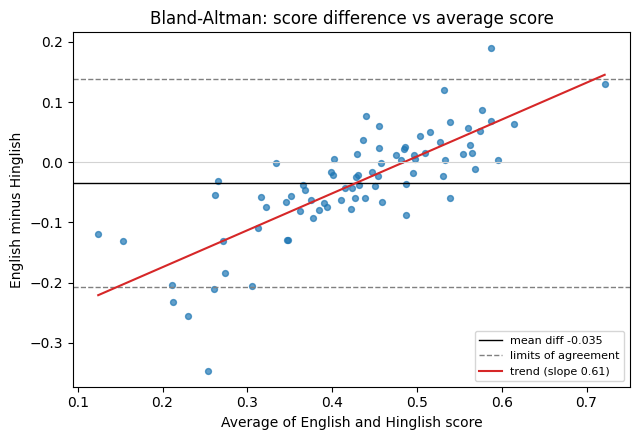

diff vs average: r = 0.793, p = 1.72e-18


In [ ]:
import matplotlib.pyplot as plt

avg = (x + y) / 2
diff = x - y
slope_ba, int_ba = np.polyfit(avg, diff, 1)
r_ba, p_ba = stats.pearsonr(avg, diff)
bias = diff.mean()
sd_d = diff.std(ddof=1)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(avg, diff, s=18, alpha=0.7)
ax.axhline(bias, color='k', lw=1, label=f'mean diff {bias:.3f}')
ax.axhline(bias + 1.96 * sd_d, color='gray', ls='--', lw=1, label='limits of agreement')
ax.axhline(bias - 1.96 * sd_d, color='gray', ls='--', lw=1)
xs = np.linspace(avg.min(), avg.max(), 50)
ax.plot(xs, slope_ba * xs + int_ba, color='C3', lw=1.5, label=f'trend (slope {slope_ba:.2f})')
ax.axhline(0, color='lightgray', lw=0.8)
ax.set_xlabel('Average of English and Hinglish score')
ax.set_ylabel('English minus Hinglish')
ax.set_title('Bland-Altman: score difference vs average score')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{BASE}/results/bland_altman_v1.png', dpi=200)
plt.show()
print(f'diff vs average: r = {r_ba:.3f}, p = {p_ba:.2e}')
# NOTE: this correlation carries the same information as Pitman-Morgan in the previous
# cell (cov(x-y, x+y) = var(x) - var(y)). Report them as one finding, not two.

In [ ]:
def crossover(xv, yv):
    s, i = np.polyfit(xv, yv, 1)
    return i / (1 - s) if abs(1 - s) > 1e-6 else np.nan   # English score where HI == EN

cross_hat = crossover(x, y)
boot = np.array([crossover(x[b], y[b]) for b in idx])
boot = boot[np.isfinite(boot)]
clo, chi = np.percentile(boot, [2.5, 97.5])
print(f'crossover English score = {cross_hat:.3f}, 95% bootstrap CI [{clo:.3f}, {chi:.3f}]')

# Orthogonal (Deming, equal error variance) slope: less sensitive than OLS to noise in x
def tls_slope(xv, yv):
    xc, yc = xv - xv.mean(), yv - yv.mean()
    sxx, syy, sxy = (xc**2).sum(), (yc**2).sum(), (xc * yc).sum()
    return (syy - sxx + np.sqrt((syy - sxx)**2 + 4 * sxy**2)) / (2 * sxy)

tls = tls_slope(x, y)
tls_boot = np.array([tls_slope(x[b], y[b]) for b in idx])
tlo, thi = np.percentile(tls_boot, [2.5, 97.5])
print(f'OLS slope {np.polyfit(x, y, 1)[0]:.2f} | orthogonal slope {tls:.2f}, 95% CI [{tlo:.2f}, {thi:.2f}]')

crossover English score = 0.477, 95% bootstrap CI [0.461, 0.494]
OLS slope 0.48 | orthogonal slope 0.51, 95% CI [0.42, 0.60]


In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

rows = []
for p, t in sorted(THR.items()):
    en = scores['english_score'] >= t
    hi_ = scores['hinglish_score'] >= t
    both, neither = int((en & hi_).sum()), int((~en & ~hi_).sum())
    en_only, hi_only = int((en & ~hi_).sum()), int((~en & hi_).sum())
    pv = mcnemar([[both, en_only], [hi_only, neither]], exact=True).pvalue
    rows.append({'nominal_strong': f'{p:.0%}', 'threshold': round(t, 4),
                 'EN_strong_pct': round(100 * en.mean(), 1),
                 'HI_strong_pct': round(100 * hi_.mean(), 1),
                 'EN_only': en_only, 'HI_only': hi_only, 'p_raw': pv})
tab = pd.DataFrame(rows)
tab['p_holm'] = multipletests(tab['p_raw'], method='holm')[1]
tab['primary'] = tab['nominal_strong'].eq(f'{PRIMARY:.0%}')
print(tab.round(4).to_string(index=False))
save_versioned(tab, 'results', 'routing_gap_holm')

nominal_strong  threshold  EN_strong_pct  HI_strong_pct  EN_only  HI_only  p_raw  p_holm  primary
           10%     0.5949            8.8            1.2        6        0 0.0312  0.0938    False
           20%     0.5094           26.2           20.0        6        1 0.1250  0.2500    False
           30%     0.4651           40.0           42.5        3        5 0.7266  0.7266    False
           50%     0.4066           55.0           72.5        1       15 0.0005  0.0021     True
           70%     0.3372           72.5           90.0        0       14 0.0001  0.0006    False
saved /content/drive/MyDrive/ML_Research/results/routing_gap_holm_v1.csv (5, 9)


'/content/drive/MyDrive/ML_Research/results/routing_gap_holm_v1.csv'

In [ ]:
import os, json, hashlib, datetime, unicodedata
import numpy as np
import pandas as pd
import importlib.metadata as im

def load_table(path):
    df = pd.read_excel(path) if path.endswith('.xlsx') else pd.read_csv(path)
    return df

def clean_text(s):
    return unicodedata.normalize('NFC', str(s).strip())   # NFC keeps Devanagari consistent

def file_hash(path):
    return hashlib.sha256(open(path, 'rb').read()).hexdigest()

def validate(df, text_cols, require_ok=True):
    need = ['pair_id'] + text_cols
    missing = [c for c in need if c not in df.columns]
    assert not missing, f'missing columns: {missing}'
    assert df['pair_id'].is_unique, 'duplicate pair_id'
    for c in text_cols:
        assert df[c].notna().all(), f'empty cells in {c}'
        assert (df[c].astype(str).str.strip() != '').all(), f'blank text in {c}'
    if 'english' in df and 'hinglish' in df:
        same = (df['english'].astype(str).str.strip() == df['hinglish'].astype(str).str.strip())
        assert not same.any(), f'identical English/Hinglish in pairs: {df.loc[same, "pair_id"].tolist()}'
    if require_ok:
        assert 'check_status' in df.columns, 'no check_status column: the freeze gate needs reviewer sign-off'
        bad = df[df['check_status'].astype(str).str.upper() != 'OK']
        assert bad.empty, f'{len(bad)} pairs are not marked OK by the second reviewer: {bad["pair_id"].tolist()[:15]}'
    print(f'validation passed: {len(df)} rows, columns {text_cols}')

def score_texts(texts):
    s = client.batch_calculate_win_rate(prompts=pd.Series(list(texts)), router='bert')
    return [float(v) for v in s]

def score_columns(df, text_cols):
    out = pd.DataFrame({'pair_id': df['pair_id'].values})
    for c in text_cols:
        texts = [clean_text(t) for t in df[c]]
        sc = score_texts(texts)
        # order check on first, middle, last row against single-question scoring
        for i in sorted({0, len(texts) // 2, len(texts) - 1}):
            single = float(router.calculate_strong_win_rate(texts[i]))
            assert abs(single - sc[i]) < 1e-3, f'order mismatch in {c}, row {i}'
        out[f'{c}_score'] = sc
    score_cols = [c for c in out.columns if c.endswith('_score')]
    assert out[score_cols].notna().all().all(), 'missing scores'
    assert out[score_cols].apply(lambda c: c.between(0, 1)).all().all(), 'score outside 0-1'
    return out

def token_features(df, text_cols):
    f = pd.DataFrame({'pair_id': df['pair_id'].values})
    for c in text_cols:
        texts = [clean_text(t) for t in df[c]]
        f[f'{c}_words'] = [len(t.split()) for t in texts]
        f[f'{c}_tokens'] = [len(tok.tokenize(t)) for t in texts]
        f[f'{c}_fertility'] = f[f'{c}_tokens'] / f[f'{c}_words']
    return f

def run_config(tag, input_path, extra=None):
    prev = json.load(open(f'{BASE}/results/config_v4.json'))   # thresholds live here
    cfg = {k: prev[k] for k in prev if 'threshold' in k}
    cfg.update({
        'router_checkpoint': 'routellm/bert_gpt4_augmented',
        'routellm_version': im.version('routellm'),
        'input_file': os.path.basename(input_path),
        'input_sha256': file_hash(input_path),
        'run_date_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    })
    if extra: cfg.update(extra)
    path = f'{BASE}/results/config_{tag}.json'
    assert not os.path.exists(path), f'{path} exists; pick a new tag instead of overwriting'
    json.dump(cfg, open(path, 'w'), indent=2)
    print('saved', path)
    return cfg

In [ ]:
tests = {
    'english':          'Why does the moon have phases?',
    'hinglish':         'Moon ke phases kyun hote hain?',
    'devanagari':       'चाँद के फेज़ क्यों होते हैं?',
    'mixed_script':     'Moon के phases क्यों होते हैं?',
    'scrambled':        'phases hote kyun ke Moon hain?',
    'long_text':        'Explain in detail how the moon causes tides. ' * 40,
    'with_newline':     'Write a function to reverse a string.\nUse Python.',
}
for name, t in tests.items():
    s = score_texts([clean_text(t)])[0]
    n_tok = len(tok.tokenize(clean_text(t)))
    print(f'{name:14s} score {s:.3f}  tokens {n_tok}')
    assert 0 <= s <= 1
print('pre-flight OK: router handles Devanagari, mixed script, scrambled and long inputs')

english        score 0.330  tokens 9
hinglish       score 0.346  tokens 10
devanagari     score 0.402  tokens 8
mixed_script   score 0.353  tokens 8
scrambled      score 0.438  tokens 10
long_text      score 0.726  tokens 480
with_newline   score 0.431  tokens 13
pre-flight OK: router handles Devanagari, mixed script, scrambled and long inputs


In [ ]:
# DRY RUN: run this cell, then re-run cell 3 (and 4/5 if you want), then run the reset cell
import os, shutil
import pandas as pd

BASE_REAL = BASE
BASE = BASE_REAL + '/_dryrun'
for sub in ['data', 'scores', 'features', 'results']:
    os.makedirs(f'{BASE}/{sub}', exist_ok=True)
shutil.copy(f'{BASE_REAL}/results/config_v4.json', f'{BASE}/results/config_v4.json')

test = bench[['pair_id', 'english', 'hinglish', 'difficulty']].copy()
test['task_type'] = bench['main_category']
test['written_by'] = 'test'
test['check_status'] = 'OK'
test.to_csv(f'{BASE}/data/confirmatory_v1.csv', index=False)
print('dry-run file written to', BASE)

dry-run file written to /content/drive/MyDrive/ML_Research/_dryrun


In [ ]:
CONF_PATH = f'{BASE}/data/confirmatory_v1.csv'     # change name/extension to match your file
conf = load_table(CONF_PATH)

MAIN_COLS = ['english', 'hinglish']
EXTRA_COLS = [c for c in ['hinglish_translated', 'hinglish_devanagari'] if c in conf.columns]

validate(conf, MAIN_COLS)                          # also refuses to run if any pair is not marked OK
for c in MAIN_COLS:
    conf[c] = conf[c].map(clean_text)

main_scores = score_columns(conf, MAIN_COLS)
main_scores['diff_en_minus_hi'] = main_scores['english_score'] - main_scores['hinglish_score']
meta_cols = [c for c in ['pair_id', 'task_type', 'difficulty', 'written_by'] if c in conf.columns]
main_scores = main_scores.merge(conf[meta_cols], on='pair_id')
save_versioned(main_scores, 'scores', 'scores_confirmatory')

feats = token_features(conf, MAIN_COLS)
feats['tokens_diff_en_minus_hi'] = feats['english_tokens'] - feats['hinglish_tokens']
feats['words_diff_en_minus_hi'] = feats['english_words'] - feats['hinglish_words']
feats['fert_diff_en_minus_hi'] = feats['english_fertility'] - feats['hinglish_fertility']
save_versioned(feats, 'features', 'features_confirmatory')

cfg = run_config('conf_v1', CONF_PATH, {'n_pairs': int(len(conf)), 'score_file_scope': 'confirmatory main run'})

d = main_scores['diff_en_minus_hi']
print('mean EN / HI score:', round(main_scores.english_score.mean(), 4), round(main_scores.hinglish_score.mean(), 4))
print('mean diff (EN - HI):', round(d.mean(), 4), '| English higher in', int((d > 0).sum()), 'of', len(d))

validation passed: 80 rows, columns ['english', 'hinglish']
saved /content/drive/MyDrive/ML_Research/_dryrun/scores/scores_confirmatory_v1.csv (80, 7)
saved /content/drive/MyDrive/ML_Research/_dryrun/features/features_confirmatory_v1.csv (80, 10)
saved /content/drive/MyDrive/ML_Research/_dryrun/results/config_conf_v1.json
mean EN / HI score: 0.4104 0.4451
mean diff (EN - HI): -0.0347 | English higher in 30 of 80


In [ ]:
if EXTRA_COLS:
    sub = conf.dropna(subset=EXTRA_COLS).copy()
    cols = ['english', 'hinglish'] + EXTRA_COLS
    validate(sub, cols)
    triple = score_columns(sub, cols)
    for c in EXTRA_COLS:
        triple[f'diff_en_minus_{c}'] = triple['english_score'] - triple[f'{c}_score']
    save_versioned(triple, 'scores', 'scores_triple')
    save_versioned(token_features(sub, cols), 'features', 'features_triple')
    print(triple.drop(columns='pair_id').describe().loc[['count', 'mean', 'std']].round(3))
    print('SD by version:', triple[[c for c in triple.columns if c.endswith('_score')]].std().round(3).to_dict())
else:
    print('no triple-version columns found; skip this cell')

no triple-version columns found; skip this cell


In [ ]:
rng = np.random.default_rng(0)           # fixed seed, so the control is reproducible

def scramble(t):
    w = clean_text(t).split()
    if len(w) < 3:
        return ' '.join(w)
    for _ in range(10):                  # make sure the order actually changes
        p = rng.permutation(len(w))
        if not (p == np.arange(len(w))).all():
            break
    return ' '.join(w[i] for i in p)

scr = conf[['pair_id']].copy()
scr['english_scrambled'] = conf['english'].map(scramble)
scr['hinglish_scrambled'] = conf['hinglish'].map(scramble)
scr_scores = score_columns(scr, ['english_scrambled', 'hinglish_scrambled'])
scr_scores['diff_en_minus_hi'] = scr_scores['english_scrambled_score'] - scr_scores['hinglish_scrambled_score']
save_versioned(scr, 'data', 'ood_scrambled_texts')            # keep the texts so the control is auditable
save_versioned(scr_scores, 'scores', 'scores_ood_scrambled')
print('SD scrambled EN / HI:', round(scr_scores.english_scrambled_score.std(), 4),
      round(scr_scores.hinglish_scrambled_score.std(), 4))

saved /content/drive/MyDrive/ML_Research/_dryrun/data/ood_scrambled_texts_v1.csv (80, 3)
saved /content/drive/MyDrive/ML_Research/_dryrun/scores/scores_ood_scrambled_v1.csv (80, 4)
SD scrambled EN / HI: 0.0937 0.0553


In [ ]:
OOD_PATH = f'{BASE}/data/ood_v1.csv'
if os.path.exists(OOD_PATH):
    ood = load_table(OOD_PATH)
    validate(ood, ['english', 'other'], require_ok=False)
    ood_scores = score_columns(ood, ['english', 'other'])
    ood_scores['diff_en_minus_other'] = ood_scores['english_score'] - ood_scores['other_score']
    save_versioned(ood_scores, 'scores', 'scores_ood_langpair')
    run_config('ood_v1', OOD_PATH, {'n_pairs': int(len(ood)), 'score_file_scope': 'other language pair control'})
    print('SD English / other:', round(ood_scores.english_score.std(), 4), round(ood_scores.other_score.std(), 4))
else:
    print('ood_v1 file not found; skip until the other-language pairs are written')

ood_v1 file not found; skip until the other-language pairs are written


In [ ]:
def rescore_file(path, text_cols, tag):
    df = load_table(path)
    validate(df, text_cols, require_ok=False)
    sc = score_columns(df, text_cols)
    save_versioned(sc, 'scores', f'scores_{tag}')
    run_config(tag, path, {'n_pairs': int(len(df)), 'score_file_scope': tag})
    return sc

In [ ]:
BASE = BASE_REAL
print(BASE)

/content/drive/MyDrive/ML_Research
